# 0 — The system, and the shape of the error

**What this notebook establishes.** What 8SGE is, what its ligand is, where it
binds, and — in geometric terms rather than as an RMSD — what Boltz-2 gets wrong
about it. The short version: the model finds the right pocket, anchors the right
end of the molecule to within half an ångström, builds a chemically reasonable
conformer, and gets the *handedness of one bond* wrong. Everything downstream of
that is a consequence.

**What it needs.** `numpy`, `matplotlib` and this repository. No GPU, no Boltz
install, no checkpoint, and no chemistry toolkit: the connectivity is read off the
deposited coordinates. The one depiction that was drawn with rdkit is a committed
figure, included below as an image.

Read it first. Notebook 1 then recomputes the baseline rate from the same
coordinates and pins the criterion the rest of the repository scores by.

In [1]:
import csv, gzip, sys, pathlib
import numpy as np
import matplotlib.pyplot as plt

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
            if (p / 'src' / 'cofolding_tts').is_dir())
sys.path.insert(0, str(ROOT / 'src'))      # unneeded after `pip install -e .`

from cofolding_tts import basin
from cofolding_tts.pose import kabsch

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11.5,
                     'axes.labelsize': 11.5, 'axes.titlesize': 12.5,
                     'xtick.labelsize': 10.5, 'ytick.labelsize': 11,
                     'figure.dpi': 160, 'savefig.dpi': 160})
GREEN, ORANGE, GREY, BLUE, INK = '#009e73', '#d55e00', '#8a93a0', '#0072b2', '#333333'
REF = ROOT / 'data' / 'reference' / '8sge'

poses = np.load(ROOT / 'data' / 'poses' / '8sge_poses.npz', allow_pickle=True)
names = [str(n) for n in poses['atom_names']]
elements = [str(e) for e in poses['elements']]
crystal = poses['crystal']                       # the deposited ligand, 33 heavy atoms
idx = {n: i for i, n in enumerate(names)}

# Bonds are not stored anywhere: take them from the deposited geometry, which is
# what makes this notebook independent of a chemistry toolkit.
D = np.linalg.norm(crystal[:, None] - crystal[None], axis=2)
BONDS = [(i, j) for i in range(len(names)) for j in range(i + 1, len(names))
         if D[i, j] < 1.75]
print(f'{len(names)} heavy atoms, {len(BONDS)} bonds, '
      f'formula C{elements.count("C")}N{elements.count("N")}O{elements.count("O")}')

33 heavy atoms, 35 bonds, formula C23N3O7


## The entry

**PDB 8SGE** — human KLHDC2 (the Kelch-domain substrate receptor of a CRL2 E3
ligase) bound to the small molecule **ZWS**, called KDRLKZ-1 by its depositors.
X-ray, 1.51 Å, from Hickey et al., *Nat. Struct. Mol. Biol.* **31**, 311–322
(2024), *Co-opting the E3 ligase KLHDC2 for targeted protein degradation by small
molecules* — the ligands in that paper were the starting point for KLHDC2-recruiting
degraders. The deposited chemical name is

> [(5P)-5-{3-[(2R)-butan-2-yl]-7-[(2-methoxyethoxy)carbonyl]-2-oxo-5,6,7,8-tetrahydro-1,7-naphthyridin-1(2H)-yl}-2-oxopyridin-1(2H)-yl]acetic acid

and **`(5P)` is the whole subject of this repository**: an axial descriptor, not a
tetrahedral one. The isomeric SMILES the models are given does not carry it.

What is vendored here is one protein chain and one copy of the ligand, enough to
run and to score; `data/reference/8sge/PROVENANCE.md` lists the files.

In [2]:
# A deliberately small reader for the two mmCIF files vendored here: one row per
# atom, fixed columns, no dependency on a parser.
def atoms(path, record='ATOM'):
    out = []
    for line in path.read_text().splitlines():
        if line.startswith(record):
            f = line.split()
            out.append((f[1], f[2], f[3], int(f[13]),
                        float(f[8]), float(f[9]), float(f[10])))
    return out                      # element, atom name, residue, number, x, y, z


prot = atoms(REF / 'system.cif')
PX = np.array([[a[4], a[5], a[6]] for a in prot])
rid = np.array([a[3] for a in prot])
rnm = np.array([a[2] for a in prot])
seq = ''.join(l.strip() for l in (REF / 'sequences.fasta').read_text().splitlines()
              if not l.startswith('>'))

print(f'protein   : {len(set(rid))} residues modelled ({rid.min()}-{rid.max()}), '
      f'{len(prot)} atoms; {len(seq)} residues in the sequence given to the model')
print(f'ligand    : {len(names)} heavy atoms')
with gzip.open(REF / 'msa_1A.csv.gz', 'rt') as fh:
    msa_rows = sum(1 for _ in fh) - 1                  # minus the header
print(f'MSA       : {msa_rows} sequences, gzipped in data/reference/8sge/')

# The pocket: every residue with an atom within 4.5 A of a deposited ligand atom.
mind = np.linalg.norm(PX[:, None] - crystal[None], axis=2).min(axis=1)
best = {}
for r, n, m in zip(rid, rnm, mind):
    best[(r, n)] = min(best.get((r, n), 9e9), m)
contact = sorted(k for k, v in best.items() if v < 4.5)
print(f'\npocket    : {len(contact)} residues within 4.5 A of the ligand')
print('           ' + ', '.join(f'{n.title()}{r}' for r, n in contact))
print(f'\nthey run from residue {contact[0][0]} to {contact[-1][0]} of {rid.max()}, in '
      f'{len({r // 60 for r, _ in contact})} different stretches of the chain: the site is\n'
      f'shared between blades of the propeller rather than sitting inside one of them.')

protein   : 326 residues modelled (26-360), 2627 atoms; 362 residues in the sequence given to the model
ligand    : 33 heavy atoms
MSA       : 2633 sequences, gzipped in data/reference/8sge/

pocket    : 17 residues within 4.5 A of the ligand
           Tyr50, Ser92, Lys147, Tyr163, Thr180, Trp191, Ala219, Ala220, Arg236, Arg241, Ser269, Trp270, Lys291, Trp321, Leu342, Leu343, His345

they run from residue 50 to 345 of 360, in 6 different stretches of the chain: the site is
shared between blades of the propeller rather than sitting inside one of them.


## The molecule

Three pieces, and it is worth keeping them apart because the model treats them
very differently:

| piece | atoms | what it is |
| --- | --- | --- |
| **acid pyridinone** | `C11`–`C17`, `N2`, `O1`–`O3` | a 2-oxopyridine with an acetic acid on its nitrogen; this is the end that binds |
| **bicyclic core** | `N1`, `C1`–`C10`, `C18`, `O` | the tetrahydronaphthyridinone, with the (2R)-butan-2-yl group |
| **carbamate tail** | `C19`–`C22`, `O4`–`O6` | the methoxyethyl carbamate, flexible and solvent-facing |

The two ring systems are joined by **one single bond, `N1`–`C11`**, from the lactam
nitrogen of the core to C11 of the acid pyridinone. Both flanks of that bond carry
substituents, so the rings cannot rotate past each other: it is a **stereogenic
axis**, and `(5P)` names which of its two senses the crystal has. The order
parameter used everywhere in this repository is the dihedral
**C12–C11–N1–C3** about that bond, which the deposited structure puts at −101.4°.

![the ligand, with the axis marked](../results/figures/8sge_compound.png)

*`results/figures/8sge_compound.png`, drawn by `scripts/figure_compound.py` with
rdkit: the hindered axis in blue, the one tetrahedral centre in orange.*

In [3]:
ACID = ['C11', 'C12', 'C13', 'C14', 'C15', 'N2', 'O1', 'C16', 'C17', 'O2', 'O3']
TAIL = ['C19', 'O4', 'O5', 'C20', 'C21', 'O6', 'C22']
CORE = [n for n in names if n not in ACID + TAIL]


def dihedral(xyz, four):
    a, b, c, d = (xyz[idx[n]] for n in four)
    b0, b1, b2 = a - b, c - b, d - c
    b1 = b1 / np.linalg.norm(b1)
    v = b0 - np.dot(b0, b1) * b1
    w = b2 - np.dot(b2, b1) * b1
    return float(np.degrees(np.arctan2(np.dot(np.cross(b1, v), w), np.dot(v, w))))


print(f'fragments : acid {len(ACID)} atoms, core {len(CORE)}, tail {len(TAIL)}')
print(f'C12-C11-N1-C3 in the deposited ligand: {dihedral(crystal, ("C12", "C11", "N1", "C3")):+.1f} deg'
      f'   (axis.CRYSTAL_TORSION = {basin.CRYSTAL_TORSION:+.1f})')
def plane_normal(members):
    x = crystal[[idx[n] for n in members]]
    return np.linalg.svd(x - x.mean(0))[2][2]


inter = np.degrees(np.arccos(abs(plane_normal(['C11', 'C12', 'N2', 'C13', 'C14', 'C15'])
                                 @ plane_normal(['N1', 'C3', 'C2', 'C6', 'C5', 'C4']))))
print(f'the two ring planes meet at {inter:.0f} deg: close to perpendicular, which is what '
      f'a hindered axis looks like')

fragments : acid 11 atoms, core 15, tail 7
C12-C11-N1-C3 in the deposited ligand: -101.4 deg   (axis.CRYSTAL_TORSION = -101.4)
the two ring planes meet at 76 deg: close to perpendicular, which is what a hindered axis looks like


## Where it binds, and what the model does with it

The left panel is the deposited complex: a 8 Å slab through the site, in the plane
of the ligand, protein atoms as discs. The right panel is the **median unperturbed
Boltz-2 draw** in the same frame, with the crystal left faint behind it.

It is the same pocket. The acid end is in the same place. The draw is 6.8 Å from
the crystal all the same.

wrote results/figures/nb00_pocket.png


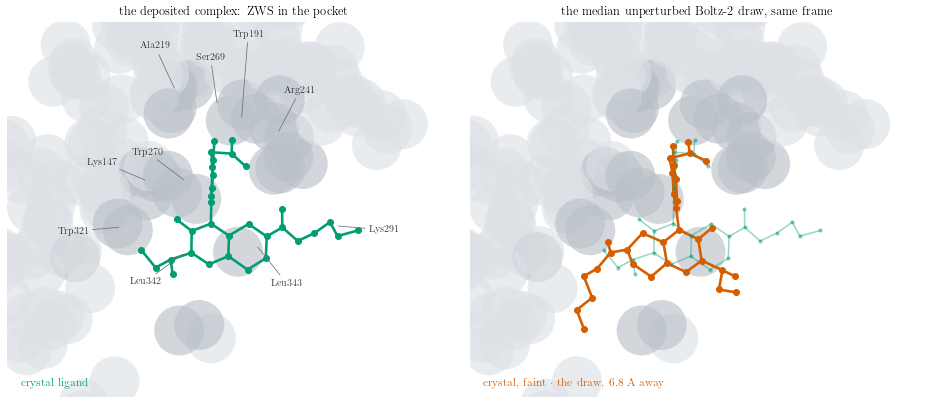

In [4]:
ctl = poses['arm'] == 'control'
label = basin.classify(poses['torsion'][ctl])
wrong = poses['coords'][ctl][label == 'wrong']
wrong_rmsd = poses['rmsd'][ctl][label == 'wrong']
rep = wrong[np.argsort(wrong_rmsd)[len(wrong_rmsd) // 2]]        # the median wrong draw


def sticks(ax, xy, colour, lw=2.6, ms=6.0, z=4, alpha=1.0):
    for i, j in BONDS:
        ax.plot(xy[[i, j], 0], xy[[i, j], 1], '-', color=colour, lw=lw, alpha=alpha,
                solid_capstyle='round', zorder=z)
    ax.plot(xy[:, 0], xy[:, 1], 'o', ms=ms, color=colour, alpha=alpha, zorder=z + 1)


cen = crystal.mean(0)
F = np.linalg.svd(crystal - cen)[2]          # the ligand's own frame; row 2 is the normal
rel = (PX - cen) @ F.T
slab = (np.abs(rel[:, 2]) < 4.0) & (np.linalg.norm(rel[:, :2], axis=1) < 16)
close = slab & (mind < 4.5)

fig, axes = plt.subplots(1, 2, figsize=(12.8, 5.6), constrained_layout=True)
for ax in axes:
    for q, near in zip(rel[slab, :2], close[slab]):
        ax.add_patch(plt.Circle(q, 1.6, facecolor='#b9c0c8' if near else '#dde1e6',
                                edgecolor='none', alpha=0.62, zorder=1))
    ax.set_aspect('equal'); ax.axis('off')
    ax.set_xlim(-14.5, 14.5); ax.set_ylim(-11.5, 12.5)

L = (crystal - cen) @ F.T
sticks(axes[0], L[:, :2], GREEN)
sticks(axes[1], L[:, :2], GREEN, lw=1.6, ms=3.2, alpha=0.40)
sticks(axes[1], ((rep - cen) @ F.T)[:, :2], ORANGE)

placed = []                                  # greedy, so two labels never collide
for (r, n) in sorted(contact, key=lambda k: best[k]):
    q = rel[(rid == r) & (mind < 4.5)][:, :2].mean(0)
    d = q - L[:, :2].mean(0)
    d = d / (np.linalg.norm(d) + 1e-9)
    for reach in (3.2, 4.4, 5.6):
        at = q + d * reach
        if all(np.linalg.norm(at - o) > 2.6 for o in placed) and np.abs(at).max() < 13.5:
            axes[0].annotate(f'{n.title()}{r}', xy=q, xytext=at, fontsize=10, color=INK,
                             ha='center', va='center', zorder=7,
                             arrowprops=dict(arrowstyle='-', color='#6f767e', lw=0.8,
                                             shrinkA=2, shrinkB=4))
            placed.append(at)
            break
    if len(placed) == 10:
        break

axes[0].set_title('the deposited complex: ZWS in the pocket', pad=6)
axes[1].set_title('the median unperturbed Boltz-2 draw, same frame', pad=6)
axes[0].annotate('crystal ligand', (0.03, 0.02), xycoords='axes fraction', color=GREEN,
                 fontsize=11.5, va='bottom')
axes[1].annotate('crystal, faint  ·  the draw, 6.8 A away', (0.03, 0.02),
                 xycoords='axes fraction', color=ORANGE, fontsize=11.5, va='bottom')
out = ROOT / 'results' / 'figures' / 'nb00_pocket.png'
fig.savefig(out, bbox_inches='tight')
print('wrote', out.relative_to(ROOT))

## What is actually wrong with the draw

Four measurements, each one ruling something out. Together they say the model did
not miss the pocket, did not misplace the anchor and did not build a bad molecule —
it built the other atropisomer.

In [5]:
def contacts_of(lig):
    m = np.linalg.norm(PX[:, None] - lig[None], axis=2).min(axis=1)
    return {(r, n) for r, n, v in zip(rid, rnm, m) if v < 4.5}


C = set(contact)
keep = np.array([len(contacts_of(w) & C) for w in wrong])
off = np.array([np.linalg.norm(w.mean(0) - crystal.mean(0)) for w in wrong])
free = np.array([kabsch(w, crystal)[2] for w in wrong])          # placement removed

# The same molecule with that one bond turned: rotate everything on the C11 side
# about N1-C11, by the angle between the two basin centres.
side = {idx['C11']}
stack = [idx['C11']]
while stack:                                      # walk the graph without crossing N1
    u = stack.pop()
    for i, j in BONDS:
        v = j if i == u else i if j == u else None
        if v is not None and v != idx['N1'] and v not in side:
            side.add(v); stack.append(v)
side = sorted(side)
ax_v = crystal[idx['C11']] - crystal[idx['N1']]
ax_v = ax_v / np.linalg.norm(ax_v)
th = np.radians(basin.WRONG_CENTRE - basin.CRYSTAL_TORSION)
turned = crystal.copy()
v = crystal[side] - crystal[idx['C11']]
turned[side] = (crystal[idx['C11']] + v * np.cos(th) + np.cross(ax_v, v) * np.sin(th)
                + ax_v * (v @ ax_v)[:, None] * (1 - np.cos(th)))
free_turned = np.array([kabsch(w, turned)[2] for w in wrong])

print(f'{len(wrong)} of the {ctl.sum()} unperturbed draws are in the wrong basin; '
      f'{(label == "correct").sum()} in the crystal\'s, {(label == "neither").sum()} in neither\n')
print(f'1. the pocket is right   : {np.median(keep):.0f} of the {len(C)} contact residues '
      f'are still touched (range {keep.min()}-{keep.max()})')
print(f'2. the placement is right: ligand centroid {np.median(off):.2f} A from the '
      f'deposited one (range {off.min():.2f}-{off.max():.2f})')
print(f'3. the molecule is right : as a free molecule, {np.median(free):.2f} A from the '
      f'crystal conformer,\n'
      f'                           but {np.median(free_turned):.2f} A from that conformer '
      f'with C12-C11-N1-C3 turned by {basin.WRONG_CENTRE - basin.CRYSTAL_TORSION:+.0f} deg')
print(f'4. and yet              : {np.median(wrong_rmsd):.2f} A ligand RMSD, because the '
      f'two ends swap places\n')
disp = np.array([np.linalg.norm(w - crystal, axis=1) for w in wrong])
for nm, frag in (('acid pyridinone', ACID), ('bicyclic core', CORE), ('carbamate tail', TAIL)):
    i = [idx[n] for n in frag]
    print(f'   {nm:>16}: {len(frag):2d} atoms, median displacement '
          f'{np.median(disp[:, i]):5.2f} A')

39 of the 41 unperturbed draws are in the wrong basin; 1 in the crystal's, 1 in neither

1. the pocket is right   : 15 of the 17 contact residues are still touched (range 13-16)
2. the placement is right: ligand centroid 2.10 A from the deposited one (range 1.71-2.51)
3. the molecule is right : as a free molecule, 2.54 A from the crystal conformer,
                           but 1.44 A from that conformer with C12-C11-N1-C3 turned by +170 deg
4. and yet              : 6.77 A ligand RMSD, because the two ends swap places

    acid pyridinone: 11 atoms, median displacement  0.49 A
      bicyclic core: 15 atoms, median displacement  4.33 A
     carbamate tail:  7 atoms, median displacement 12.69 A


That is the whole failure. The acid end is pinned — half an ångström, the width of
a thermal wobble — and the bicyclic core is swung round the axis to the other side,
taking the solvent-facing tail 13 Å with it. Average that over 33 atoms and you get
6.8 Å, which is what a scoring table reports, and which sounds like a model that
has no idea where the ligand goes. It is the opposite: the model is confident, and
confidently handed.

The left-hand panels below are the two senses of the bond, drawn end on as Newman
projections. The right-hand panel is where the error lives, atom by atom.

Newman angles: crystal -101.4 deg, draw +66.0 deg  (deposited -101.4, wrong basin centre +68.7)


wrote results/figures/nb00_flip.png


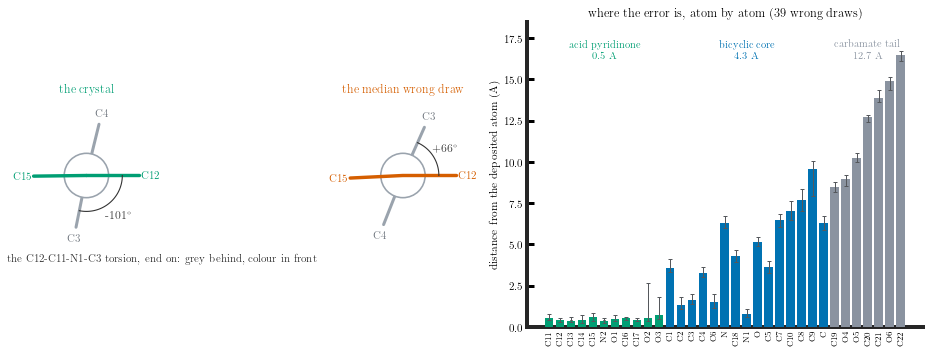

In [6]:
R, t, _ = kabsch(rep[[idx[n] for n in ACID]], crystal[[idx[n] for n in ACID]])
fit = rep @ R.T + t                              # the draw, superposed on its acid ring

fig = plt.figure(figsize=(12.8, 4.8), constrained_layout=True)
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 2.5])
ax0, ax1, bx = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]), fig.add_subplot(gs[2])


# The axis end on: C11 in front carrying C12 and C15, N1 behind carrying C3 and C4.
def newman(ax, xyz, title, colour):
    o = xyz[idx['C11']]
    z = xyz[idx['N1']] - o; z = z / np.linalg.norm(z)       # the viewing direction
    ref = xyz[idx['C12']] - o
    x = ref - np.dot(ref, z) * z; x = x / np.linalg.norm(x)
    frame = np.vstack([x, np.cross(z, x)])

    def unit(name, origin):
        v = (xyz[idx[name]] - xyz[idx[origin]]) @ frame.T
        return v / np.linalg.norm(v)

    ax.add_patch(plt.Circle((0, 0), 0.42, facecolor='white', edgecolor='#9aa3ad', lw=1.6,
                            zorder=3))
    for name in ('C3', 'C4'):                               # behind, drawn from the rim
        v = unit(name, 'N1')
        ax.plot([v[0] * 0.42, v[0]], [v[1] * 0.42, v[1]], color='#9aa3ad', lw=3.0,
                solid_capstyle='round', zorder=2)
        ax.annotate(name, v * 1.22, color='#6f767e', fontsize=11, ha='center', va='center')
    for name in ('C12', 'C15'):                             # in front, from the centre
        v = unit(name, 'C11')
        ax.plot([0, v[0]], [0, v[1]], color=colour, lw=3.4, solid_capstyle='round', zorder=4)
        ax.annotate(name, v * 1.22, color=colour, fontsize=11, ha='center', va='center')
    a0 = np.degrees(np.arctan2(*unit('C12', 'C11')[::-1]))
    a1 = np.degrees(np.arctan2(*unit('C3', 'N1')[::-1]))
    sweep = (a1 - a0 + 180) % 360 - 180
    arc = np.radians(np.linspace(a0, a0 + sweep, 120))
    ax.plot(0.68 * np.cos(arc), 0.68 * np.sin(arc), color=INK, lw=1.1, zorder=5)
    ax.annotate(f'{sweep:+.0f}' + r'$^\circ$',
                (0.95 * np.cos(arc[60]), 0.95 * np.sin(arc[60])),
                fontsize=12, color=INK, ha='center', va='center', zorder=6)
    ax.set_aspect('equal'); ax.axis('off')
    ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.45, 1.5)
    ax.set_title(title, pad=4, fontsize=12, color=colour)
    return sweep


t_cry = newman(ax0, crystal, 'the crystal', GREEN)
t_drw = newman(ax1, fit, 'the median wrong draw', ORANGE)
ax0.annotate('the C12-C11-N1-C3 torsion, end on: grey behind, colour in front',
             (0.0, -0.06), xycoords='axes fraction', fontsize=11, color=INK, ha='left')
print(f'Newman angles: crystal {t_cry:+.1f} deg, draw {t_drw:+.1f} deg  '
      f'(deposited {basin.CRYSTAL_TORSION:+.1f}, wrong basin centre {basin.WRONG_CENTRE:+.1f})')

order = [idx[n] for n in ACID + CORE + TAIL]
med = np.median(disp, axis=0)[order]
lo = np.percentile(disp, 10, axis=0)[order]
hi = np.percentile(disp, 90, axis=0)[order]
bx.bar(np.arange(len(order)), med, width=0.78, zorder=3,
       color=[GREEN] * len(ACID) + [BLUE] * len(CORE) + [GREY] * len(TAIL))
bx.errorbar(np.arange(len(order)), med, yerr=[med - lo, hi - med], fmt='none',
            ecolor='#55585c', lw=1.0, capsize=2.0, zorder=4)
bx.set_xticks(np.arange(len(order)))
bx.set_xticklabels([names[i] for i in order], rotation=90, fontsize=8.5)
bx.set_ylabel('distance from the deposited atom (A)')
bx.set_title(f'where the error is, atom by atom ({len(wrong)} wrong draws)', pad=6)
bx.spines[['top', 'right']].set_visible(False)
bx.set_ylim(0, 18.5)
x0 = 0
for frag, lab, col in ((ACID, 'acid pyridinone', GREEN), (CORE, 'bicyclic core', BLUE),
                       (TAIL, 'carbamate tail', GREY)):
    i = [idx[n] for n in frag]
    bx.annotate(f'{lab}\n{np.median(disp[:, i]):.1f} A',
                (x0 + (len(frag) - 1) / 2, 17.4), ha='center', va='top', color=col,
                fontsize=10.5)
    x0 += len(frag)
out = ROOT / 'results' / 'figures' / 'nb00_flip.png'
fig.savefig(out, bbox_inches='tight')
print('wrote', out.relative_to(ROOT))

## Is the right answer reachable at all?

8SGE is in this repository because three co-folding models, given the same
sequence, the same SMILES and the same MSA, disagree about it completely. That is
the evidence that nothing is missing from the models — the answer is inside their
reach, and which one you draw is the difference.

In [7]:
rows = [r for r in csv.DictReader((ROOT / 'data' / 'cross_model' / 'pose_lddt.csv').open())
        if r['msa'] == 'full 2633']
print(f"{'model':>11} {'n':>4} {'< 2 A':>7} {'crystal basin':>14} {'median RMSD':>12} "
      f"{'median lDDT-PLI':>16}")
for model in ('Boltz-2', 'AlphaFold3', 'Protenix'):
    sel = [r for r in rows if r['model'] == model]
    rm = np.array([float(r['ligand_rmsd_angstrom']) for r in sel])
    pli = np.array([float(r['lddt_pli']) for r in sel])
    tor = np.array([float(r['axial_torsion_deg']) for r in sel])
    n = basin.counts(tor)
    print(f'{model:>11} {len(sel):>4} {int((rm < 2).sum()):>7} '
          f"{n['correct']:>9}/{len(sel):<4} {np.median(rm):>10.2f} A {np.median(pli):>16.2f}")

bz = [r for r in rows if r['model'] == 'Boltz-2']
pli = np.array([float(r['lddt_pli']) for r in bz])
tor = np.array([float(r['axial_torsion_deg']) for r in bz])
w = basin.classify(tor) == 'wrong'
print(f'\nBoltz-2 poses in the wrong basin still score lDDT-PLI {np.median(pli[w]):.2f}: '
      f'wrong, and not obviously so from the\nmodel\'s own side — and lDDT-PLI needs the '
      f'deposited complex to compute, so it cannot be used to pick a draw.')

      model    n   < 2 A  crystal basin  median RMSD  median lDDT-PLI
    Boltz-2  100       1         3/100        6.78 A             0.59
 AlphaFold3  100      19        39/100        7.15 A             0.36
   Protenix  100      64        83/100        1.79 A             0.79

Boltz-2 poses in the wrong basin still score lDDT-PLI 0.59: wrong, and not obviously so from the
model's own side — and lDDT-PLI needs the deposited complex to compute, so it cannot be used to pick a draw.


## What this does and does not say

- **The failure is a discrete choice, not an inaccuracy.** The pocket is found, the
  anchor is placed, the conformer is sound. One bond is built the wrong way round,
  and that single decision costs 6.8 Å.
- **It is one bond with no free rotation**, so there is no continuum to refine
  along: a sampler either produces one sense or the other. Notebook 1 shows that
  nothing lands in between.
- **Three models, one target, three different answers** — Protenix 64 of 100 under
  2 Å, AlphaFold3 19, Boltz-2 1. Read `data/cross_model/PROVENANCE.md` before
  quoting any of those: sampling differs between cells, and a hit here is RMSD
  alone rather than the benchmark's stricter combined criterion.
- **This is one system.** The failure is documented across 8 systems and 3 models in
  `data/cross_model/`, but everything taken apart at this level of detail — and
  every intervention arm committed here — is 8SGE under Boltz-2 2.2.1.
- **Nothing here ranks draws.** lDDT-PLI needs the answer to compute, so it
  describes the error, it does not select against it.

Where to go next:

| notebook | question |
| --- | --- |
| `01_baseline.ipynb` | how often, exactly, and by what criterion |
| `02_baselines.ipynb` | does the same shape appear on other systems |
| `03_tcp_arms.ipynb` | what the published perturbation does about it |
| `04_committor.ipynb` | is it two basins, and how tilted is the landscape |
| `05_slig_gauss.ipynb` | our intervention: where the noise goes, and what it is worth |